# Plot KAM vs distance to GB

In [1]:
import h5py
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import distance_transform_edt, binary_dilation
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D


### Import files

In [2]:
small_microstructure = False
larger_microstructure = False
section = True

if small_microstructure:
    file_path = 'E:/Users/lagon/The University of Manchester Dropbox/Laura Gonzalez/Zr-hydrides/Lunty polish/Lunty avec tickle/Laura analysis Part 1/3D microstructure analysis'
    #file_path = 'E:/Users/lagon/The University of Manchester Dropbox/Laura Gonzalez/Zr-hydrides/Lunty polish/Lunty avec tickle/Laura analysis Part 1/Cleaning Zr with Hydrides/'
    file_name = file_path + "/4.5-Recrystallised_rotated_aligned_cleaned_KAM_boundarycells.dream3d"
    #file_name = file_path + "D3D_Lunty_avec_tickle_Part1_100nm_cleanedmicrostructure_withhydrides_IPF_KAM_distances.dream3d"
    #KAM_path = "/DataContainers/ImageDataContainer/CellData/KernelAverageMisorientations"
    KAM_path = "/DataContainers/ImageDataContainer/CellData/KAM"
    boundary_cells = "/DataContainers/ImageDataContainer/CellData/BoundaryCells"
    hydphase, Zrphase = 1, 2
    z = 850  # pick a slice that contains hydrides + GBs to visualise the threshold used for GBs flagged as far from hydrides


if larger_microstructure:
    file_path = 'E:/Users/lagon/The University of Manchester Dropbox/Laura Gonzalez/Zr-hydrides/Larger_alloy4_processing/'
    file_name = file_path + "4-LargeRecrystallised_rotated_aligned_cleaned_KAM_boundarycells.dream3d"
    KAM_path = "/DataContainers/ImageDataContainer/CellData/KAM"
    boundary_cells = "/DataContainers/ImageDataContainer/CellData/BoundaryCells"
    hydphase, Zrphase = 2, 1
    z = 850  # pick a slice that contains hydrides + GBs to visualise the threshold used for GBs flagged as far from hydrides


if section:
    file_path = 'E:/Users/lagon/The University of Manchester Dropbox/Laura Gonzalez/Zr-hydrides/Lunty polish/Lunty avec tickle/Laura analysis Part 1/3D microstructure analysis'
    file_name = file_path + "/4.5-Recrystallised_rotated_aligned_cleaned_KAM_boundarycells_cropped.dream3d"
    KAM_path = "/DataContainers/ImageDataContainer/CellData/KAM"
    boundary_cells = "/DataContainers/ImageDataContainer/CellData/BoundaryCells"
    hydphase, Zrphase = 1, 2


with h5py.File(file_name, "r") as f:
    kam_values = f[KAM_path][()]
    phases_values = f["/DataContainers/ImageDataContainer/CellData/Phases"][()]
    voxel_size = f["/DataContainers/ImageDataContainer/_SIMPL_GEOMETRY/SPACING"][()]
    phases_names = f["/DataContainers/ImageDataContainer/CellEnsembleData/MaterialName"][()]
    boundary_cells = f[boundary_cells][()]

kam_values = np.asarray(kam_values, dtype=float)
phases_values = np.asarray(phases_values)
voxel_size = np.asarray(voxel_size, dtype=float)
boundary_cells = np.array(boundary_cells)

# Check that phase number corresponds to the correct label
print(phases_names)
print(hydphase, Zrphase)

[b'Invalid Phase' b'ZircHydride' b'Zirc-alloy4']
1 2


### Tidy up data

In [3]:
def binned_mean(x, y, bins):
    idx = np.digitize(x, bins)
    means = np.full(len(bins) - 1, np.nan, dtype=float)
    for i in range(1, len(bins)):
        m = (idx == i)
        if np.any(m):
            means[i - 1] = np.mean(y[m])
    centers = (bins[:-1] + bins[1:]) / 2
    return centers, means

def to_3d_scalar(a):
    a = np.asarray(a)
    if a.ndim == 4:
        return a[..., 0]
    return a

ph  = to_3d_scalar(phases_values)
kam = to_3d_scalar(kam_values)
bc  = to_3d_scalar(boundary_cells)

zr_mask  = (ph == Zrphase)          
hyd_mask = (ph == hydphase)   
gb_all   = (bc >= 1)      

voxel_spacing = tuple(np.asarray(voxel_size, dtype=float))


## Plot average KAM crossing 3D hydride

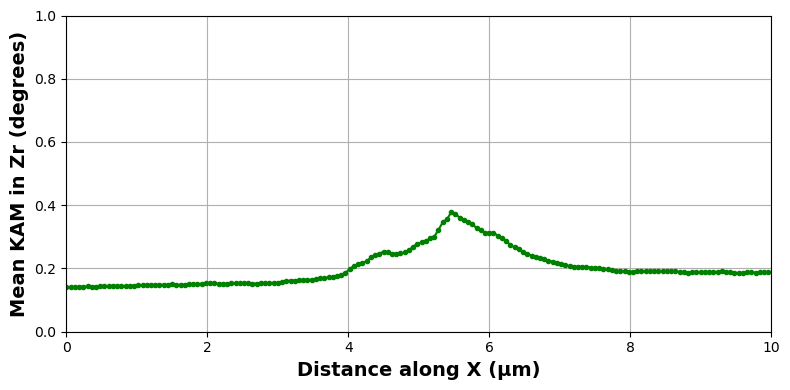

In [4]:
x_idx = np.arange(ph.shape[2])
x_um = x_idx * voxel_spacing[0]

mean_kam_zr = np.full_like(x_um, np.nan, dtype=float)

for k in range(ph.shape[2]):
    m = (ph[:, :, k] == Zrphase)
    if np.any(m):
        mean_kam_zr[k] = np.mean(kam[:, :, k][m])

plt.figure(figsize=(8, 4))
plt.plot(x_um, mean_kam_zr, marker='o', markersize=3, color='green')
plt.xlabel("Distance along X (µm)", fontsize=14, fontweight='bold')
plt.ylabel("Mean KAM in Zr (degrees)", fontsize=14, fontweight='bold')
plt.xlim(0, 10)
plt.ylim(0, 1)
plt.grid(True)
plt.tight_layout()
plt.show()


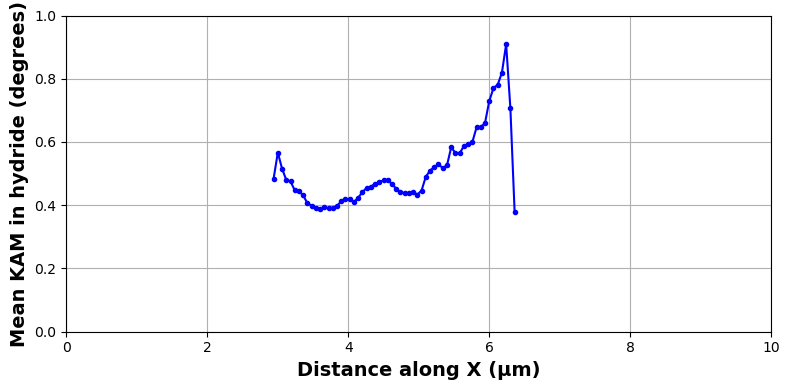

In [5]:
mean_kam_hyd = np.full_like(x_um, np.nan, dtype=float)

for k in range(ph.shape[2]):
    m = (ph[:, :, k] == hydphase)
    if np.any(m):
        mean_kam_hyd[k] = np.mean(kam[:, :, k][m])

plt.figure(figsize=(8, 4))
plt.plot(x_um, mean_kam_hyd, marker='o', markersize=3, color='blue')

plt.xlabel("Distance along X (µm)", fontsize=14, fontweight='bold')
plt.ylabel("Mean KAM in hydride (degrees)", fontsize=14, fontweight='bold')
plt.xlim(0, 10)
plt.ylim(0, 1)

plt.grid(True)
plt.tight_layout()
plt.show()


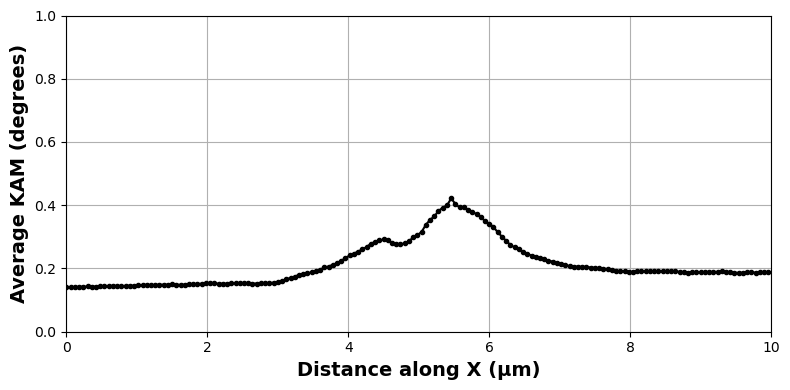

In [6]:
x_idx = np.arange(ph.shape[2])
x_um = x_idx * voxel_spacing[0]

mean_kam_all = np.full_like(x_um, np.nan, dtype=float)

for k in range(ph.shape[2]):
    # all voxels at this position
    vals = kam[:, :, k]
    if np.any(np.isfinite(vals)):
        mean_kam_all[k] = np.mean(vals[np.isfinite(vals)])

plt.figure(figsize=(8, 4))
plt.plot(x_um, mean_kam_all, marker='o', markersize=3, color='black')
#plt.plot(x_um, mean_kam_hyd, marker='o', markersize=3, color='blue')
#plt.plot(x_um, mean_kam_zr, marker='o', markersize=3, color='green')


plt.xlabel("Distance along X (µm)", fontsize=14, fontweight='bold')
plt.ylabel("Average KAM (degrees)", fontsize=14, fontweight='bold')
plt.xlim(0, 10)
plt.ylim(0, 1)
plt.grid(True)
plt.tight_layout()
plt.show()


Hydride region: 2.939999934285879 to 6.359999857842922 µm


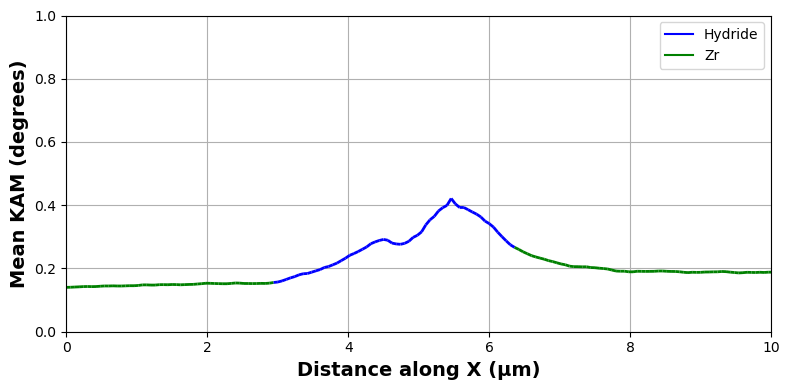

In [7]:
# indices where hydride data exists
hyd_mask_x = np.isfinite(mean_kam_hyd)

xmin_hyd = x_um[hyd_mask_x].min()
xmax_hyd = x_um[hyd_mask_x].max()

print("Hydride region:", xmin_hyd, "to", xmax_hyd, "µm")


# Remove NaNs
valid = np.isfinite(mean_kam_all)
x = x_um[valid]
y = mean_kam_all[valid]

# Build line segments
points = np.array([x, y]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)

# Colour each segment depending on x-position
segment_colors = []
for i in range(len(x) - 1):
    xm = 0.5 * (x[i] + x[i+1])  # midpoint of segment
    if xmin_hyd <= xm <= xmax_hyd:
        segment_colors.append("blue")
    else:
        segment_colors.append("green")

lc = LineCollection(segments, colors=segment_colors, linewidths=2)

plt.figure(figsize=(8, 4))
plt.gca().add_collection(lc)

#point_colors = ["blue" if (xmin_hyd <= xv <= xmax_hyd) else "green" for xv in x]
#plt.scatter(x, y, c=point_colors, marker="x", s=30, zorder=3)


handles = [
    Line2D([0], [0], color='blue', linestyle="-", label='Hydride'),
    Line2D([0], [0], color='green',  linestyle="-",  label='Zr')
]
plt.legend(handles=handles)

plt.xlabel("Distance along X (µm)", fontsize=14, fontweight='bold')
plt.ylabel("Mean KAM (degrees)", fontsize=14, fontweight='bold')
plt.xlim(0,10)
plt.ylim(0, 1)
plt.grid(True)
plt.tight_layout()
plt.show()

Hydride region: 2.939999934285879 to 6.359999857842922 µm


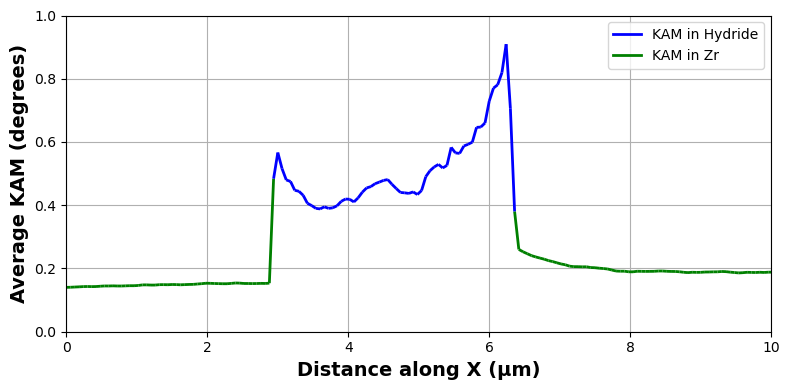

In [8]:
# --- Hydride x-range (where hydride mean exists) ---
hyd_mask_x = np.isfinite(mean_kam_hyd)
xmin_hyd = x_um[hyd_mask_x].min()
xmax_hyd = x_um[hyd_mask_x].max()
print("Hydride region:", xmin_hyd, "to", xmax_hyd, "µm")

# --- Build a combined curve:
#     green sections use mean_kam_zr, blue section uses mean_kam_hyd ---
y_combined = np.full_like(x_um, np.nan, dtype=float)

for i, xv in enumerate(x_um):
    if xmin_hyd <= xv <= xmax_hyd:
        y_combined[i] = mean_kam_hyd[i]   # hydride-only in the hydride window
    else:
        y_combined[i] = mean_kam_zr[i]    # Zr-only outside the hydride window

# --- Remove NaNs (important: keep consistent x/y lengths) ---
valid = np.isfinite(y_combined)
x = x_um[valid]
y = y_combined[valid]

# --- Build line segments ---
points = np.array([x, y]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)

# --- Color each segment by x-position ---
segment_colors = []
for i in range(len(x) - 1):
    xm = 0.5 * (x[i] + x[i+1])  # midpoint
    if xmin_hyd <= xm <= xmax_hyd:
        segment_colors.append("blue")
    else:
        segment_colors.append("green")

lc = LineCollection(segments, colors=segment_colors, linewidths=2)

plt.figure(figsize=(8, 4))
plt.gca().add_collection(lc)

handles = [
    Line2D([0], [0], color='blue', lw=2, label='KAM in Hydride'),
    Line2D([0], [0], color='green', lw=2, label='KAM in Zr')
]
plt.legend(handles=handles)

plt.xlabel("Distance along X (µm)", fontsize=14, fontweight='bold')
plt.ylabel("Average KAM (degrees)", fontsize=14, fontweight='bold')
plt.xlim(0, 10)
plt.ylim(0, 1)
plt.grid(True)
plt.tight_layout()
plt.show()


## Plot KAM vs distance to hyd-Zr GB and vs distance to Zr-Zr GB

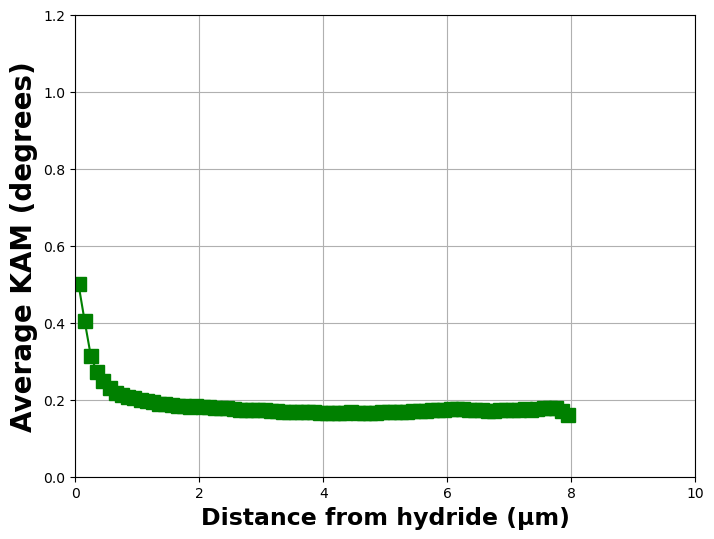

In [ ]:
#  ZR–HYD GB DISTANCES 

# GB voxels on the Zr side (includes Zr-Zr and Zr-hyd)
gb_in_zr = gb_all & zr_mask

# Define "touching hydride" using a 3x3x3 neighborhood (includes diagonals)
hyd_touch = binary_dilation(hyd_mask, structure=np.ones((3, 3, 3), dtype=bool))

# Case 2 mask: Zr-hyd GB voxels = GB voxels in Zr that touch hydride
gb_zr_hyd = gb_in_zr & hyd_touch

voxel_spacing = tuple(np.asarray(voxel_size, dtype=float))

# Distance from each Zr voxel to nearest Zr-hyd GB voxel
dist_gb_hyd_vol = distance_transform_edt(~gb_zr_hyd, sampling=voxel_spacing)
dist_gb_hyd = dist_gb_hyd_vol[zr_mask]

# Matching Zr KAM values
kam_zr = kam[zr_mask]

# --- Bin + mean ---
bin_width = 0.1
max_dist = 30.0
bins = np.arange(0.0, max_dist + bin_width, bin_width)

bin_centers_hydgb, bin_means_hydgb = binned_mean(dist_gb_hyd, kam_zr, bins)

# ZR–ZR GB DISTANCES, only those >= 2.4 µm from hydrides

kam_zr = kam[zr_mask] # KAM for Zr voxels 


gb_in_zr = gb_all & zr_mask # Zr–Zr GB voxels 

# "Touches hydride" in a 3x3x3 neighborhood (includes diagonals)
hyd_touch = binary_dilation(hyd_mask, structure=np.ones((3,3,3), dtype=bool))

# Zr–Zr GB = GB voxels in Zr that do NOT touch hydride
gb_zr_zr = gb_in_zr & (~hyd_touch)

# Distance-to-hydride
dist_to_hyd_um_vol = distance_transform_edt(~hyd_mask, sampling=voxel_spacing)

# Threshold: keep only Zr–Zr GB voxels >= 2.4 microns from hydrides
R_um = 2.4

# distance to hydride everywhere 
dist_to_hyd_um_vol = distance_transform_edt(~hyd_mask, sampling=voxel_spacing)

# clean GB voxels
gb_zr_zr_far = gb_zr_zr & (dist_to_hyd_um_vol >= R_um)

# recompute distance to clean GB
dist_to_gb_far_vol = distance_transform_edt(~gb_zr_zr_far, sampling=voxel_spacing)

# important! only consider Zr voxels that are also far from hydrides
zr_far_mask = zr_mask & (dist_to_hyd_um_vol >= R_um)

kam_zr_far = kam[zr_far_mask]
dist_to_gb_far = dist_to_gb_far_vol[zr_far_mask]

bin_centers, bin_means = binned_mean(dist_to_gb_far, kam_zr_far, bins)
m = ~np.isnan(bin_means)

plt.figure(figsize=(8, 6))


if small_microstructure or larger_microstructure:
    plt.xlabel("Distance from hydrides or grain boundary (µm)", fontsize=17, fontweight='bold')
    plt.plot(bin_centers, bin_means, marker='o', color='black', markersize=10, label=f'distance from GB')
    plt.plot(bin_centers_hydgb, bin_means_hydgb, marker='s', color='green', markersize=10, label='distance from hydride')
    plt.legend(fontsize=20)


if section:
    plt.xlabel("Distance from hydride (µm)", fontsize=17, fontweight='bold')
    plt.plot(bin_centers_hydgb, bin_means_hydgb, marker='s', color='green', markersize=10)


plt.ylabel("Average KAM (degrees)", fontsize=20, fontweight='bold')


plt.xlim([0, 10])
plt.ylim([0, 1.2])
plt.grid(True)

plt.show()


In [10]:
print("zr_mask:", zr_mask.shape)
print("hyd_mask:", hyd_mask.shape)
print("gb_zr_zr:", gb_zr_zr.shape)
print("dist_to_hyd_um_vol:", dist_to_hyd_um_vol.shape)

zr_mask: (107, 54, 169)
hyd_mask: (107, 54, 169)
gb_zr_zr: (107, 54, 169)
dist_to_hyd_um_vol: (107, 54, 169)


### Plot KAM vs distance to hydride and vs distance to any GB, including hyd-zr and zr-zr GBs

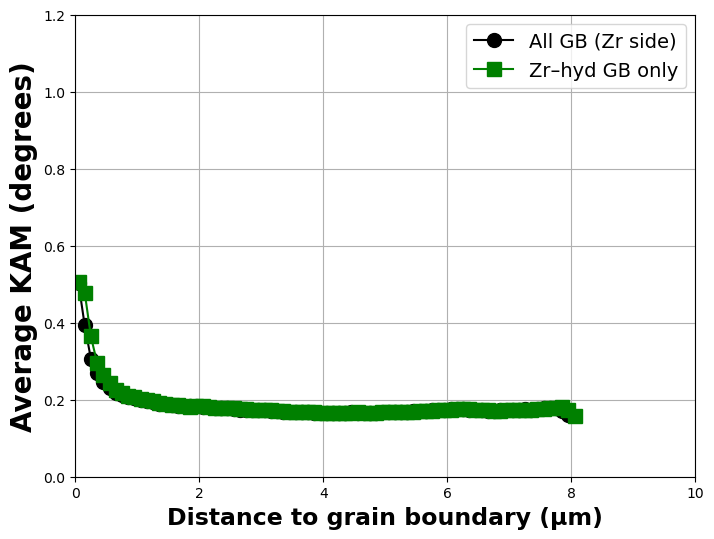

GB in Zr: 18080


In [11]:
             
gb_in_zr = gb_all & zr_mask

# Hydride-touch region 
hyd_touch = binary_dilation(hyd_mask, structure=np.ones((3, 3, 3), dtype=bool))



voxel_spacing = tuple(np.asarray(voxel_size, dtype=float))


dist_to_hyd = distance_transform_edt(~hyd_mask, sampling=voxel_spacing)[zr_mask]
dist_gb = distance_transform_edt(~gb_all, sampling=voxel_spacing)[zr_mask]

# Matching Zr KAM values
kam_zr = kam[zr_mask]

# --- Bin + mean ---
bin_width = 0.1
max_dist = 30.0
bins = np.arange(0.0, max_dist + bin_width, bin_width)

bin_centers, bin_means = binned_mean(dist_gb, kam_zr, bins)
bin_centers_tohyd, bin_means_tohyd = binned_mean(dist_to_hyd, kam_zr, bins)


plt.figure(figsize=(8, 6))
plt.plot(bin_centers, bin_means, marker='o', color='black', markersize=10, label='All GB (Zr side)')
plt.plot(bin_centers_tohyd, bin_means_tohyd, marker='s', color='green', markersize=10, label='Zr–hyd GB only')
#plt.plot(bin_centers_zrgb[m], bin_means_zrgb[m], marker='^', color='blue', markersize=10, label='Zr–Zr GB only')
plt.xlabel("Distance to grain boundary (µm)", fontsize=17, fontweight='bold')
plt.ylabel("Average KAM (degrees)", fontsize=20, fontweight='bold')
plt.xlim([0, 10])
plt.ylim([0, 1.2])
plt.grid(True)
plt.legend(fontsize=14)
plt.show()

print("GB in Zr:", np.count_nonzero(gb_in_zr))


## Plot slice to test

In [12]:
if small_microstructure or larger_microstructure:
    fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)
    z = 85
    # 1) Phases
    axes[0].imshow(ph[:, :, z], cmap='gray')
    axes[0].set_title("Hydrides")

    # 2) All GB voxels
    axes[1].imshow(gb_in_zr[:, :, z], cmap='gray')
    axes[1].set_title("All GB in Zr")

    # 3) Zr–hyd GB
    axes[2].imshow(gb_zr_hyd[:, :, z], cmap='gray')
    axes[2].set_title("Zr–hyd GB")

    # 4) Zr–Zr GB
    axes[3].imshow(gb_zr_zr[:, :, z], cmap='gray')
    axes[3].set_title("Zr–Zr GB")

    # 5) Zr–Zr GB ≥ 10 vox from hyd
    axes[4].imshow(gb_zr_zr_far[:, :, z], cmap='gray')
    axes[4].set_title("Zr–Zr GB far from hyd")

    for ax in axes:
        ax.axis('off')

    plt.tight_layout()
    plt.show()


### Slice showing both types of GB before thresholding

In [13]:
if small_microstructure or larger_microstructure:
    plt.figure(figsize=(5,5))
    plt.imshow(ph[:, :, z], cmap='gray')
    plt.imshow(gb_zr_hyd[:, :, z], cmap='Reds', alpha=0.7)
    plt.imshow(gb_zr_zr[:, :, z], cmap='Blues', alpha=0.7)

    plt.title("Overlay: Red = Zr–hyd GB, Blue = clean Zr–Zr GB")
    plt.axis('off')
    plt.show()


### Slice showing both types of GB after thresholding

In [14]:
if small_microstructure or larger_microstructure:
    plt.figure(figsize=(5,5))
    plt.imshow(ph[:, :, z], cmap='gray')
    plt.imshow(gb_zr_hyd[:, :, z], cmap='Reds', alpha=0.7)
    plt.imshow(gb_zr_zr_far[:, :, z], cmap='Blues', alpha=0.7)
    plt.title("Overlay: Red = Zr–hyd GB, Blue = clean Zr–Zr GB")
    plt.axis('off')
    plt.show()